# Ming–Qing Ledgers: how imperial China counted value

*Résumé : comment la Chine des Ming et des Qing comptait les foyers, l'argent et les stocks, et ce qu'il en reste dans la comptabilité des actifs de données en 2024.*

**Question.** How did the Ming (1368–1644) and Qing (1644–1912) states record people, land, money and stock, and which of their accounting identities still run today?

**Sources.** Two open-access papers by M. A. Amurskaya (Financial University, Moscow), *Accounting and statistics in China during the Ming dynasty* and *Accounting and statistics in China under the Qing dynasty*, *Accounting. Analysis. Auditing* 9(2) and 9(6), 2022, CC BY 4.0. They synthesise mostly Chinese-language scholarship. The tables in `data/` are transcribed or structured from them. The 2024 bridge comes from the Ministry of Finance interim provisions on enterprise data resources.

**Limits up front.** One secondary author, read in translation; a few dates differ from other literature and are flagged. Sections 3 and 4 use **synthetic** figures to show the mechanics, not historical accounts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path('../data'); FIG = Path('../outputs/figures'); FIG.mkdir(parents=True, exist_ok=True)
INK, MUTED, GRID, BG = '#1F2328', '#6E7781', '#E6E6E3', '#FCFCFB'
LAND, WATER = '#B33A2B', '#2F5E9E'   # palette validated for colour-vision deficiency
plt.rcParams.update({'font.family': 'Inter', 'font.size': 10, 'axes.edgecolor': GRID,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': INK, 'figure.facecolor': BG,
    'axes.facecolor': BG, 'savefig.facecolor': BG, 'axes.spines.top': False, 'axes.spines.right': False})

tables = {p.stem: pd.read_csv(p) for p in sorted(DATA.glob('*.csv'))}
tables['thinkers'][['born', 'died']] = tables['thinkers'][['born', 'died']].astype('Int64')
{k: v.shape for k, v in tables.items()}

{'ledger_methods': (5, 9), 'registers': (9, 7), 'relay_stations': (17, 6), 'reporting_calendar': (9, 5), 'thinkers': (9, 7), 'timeline': (15, 4)}

## 1. The relay network: does the table add up?

The Ming state moved documents, and therefore accounts, through 1,035 relay stations. Before reading the table, check it.

In [2]:
rs = tables['relay_stations']
totals = rs[['stations_total', 'land_stations', 'water_stations', 'delivery_posts']].sum()
assert (rs.land_stations + rs.water_stations == rs.stations_total).all()   # every row closes
assert tuple(totals) == (1035, 823, 212, 145)                              # matches the published totals
rs['water_share'] = rs.water_stations / rs.stations_total
totals.to_dict(), rs.sort_values('water_share', ascending=False)[['region', 'stations_total', 'water_share']].head(5).round(2)

({'stations_total': 1035, 'land_stations': 823, 'water_stations': 212, 'delivery_posts': 145},        region  stations_total  water_share
13  Guangdong              75         0.47
4    Zhejiang              33         0.42
5     Jiangxi              40         0.40
12    Sichuan             141         0.34
6     Huguang             111         0.32)

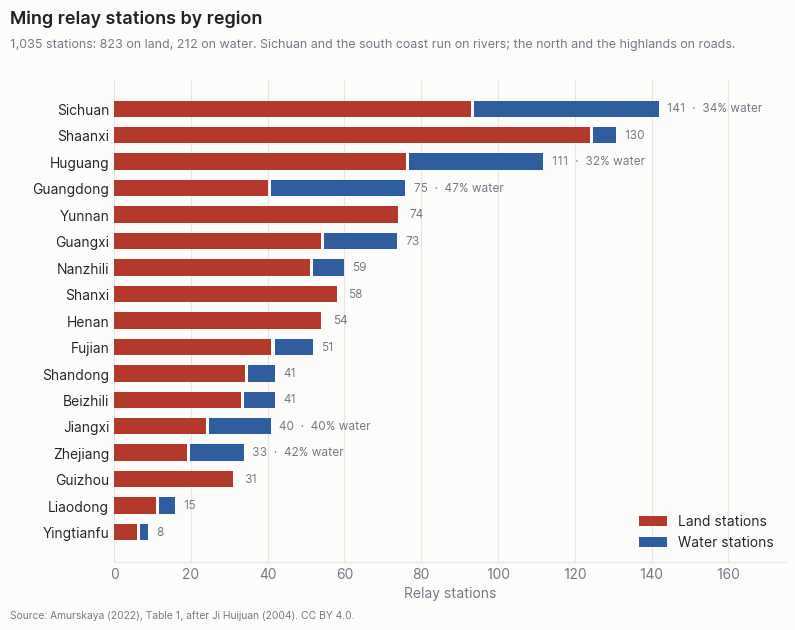

In [3]:
d = rs.sort_values('stations_total')
fig, ax = plt.subplots(figsize=(8, 6.2))
ax.barh(d.region, d.land_stations, color=LAND, height=0.62, label='Land stations')
ax.barh(d.region, d.water_stations, left=d.land_stations + 0.8, color=WATER, height=0.62, label='Water stations')
for y, (t, w) in enumerate(zip(d.stations_total, d.water_share)):
    ax.text(t + 3, y, f'{t}' + (f'  ·  {w:.0%} water' if w >= 0.3 else ''), va='center', color=MUTED, fontsize=8.5)
ax.set_xlim(0, 175); ax.xaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.tick_params(length=0); ax.spines['left'].set_visible(False)
ax.set_xlabel('Relay stations')
ax.legend(frameon=False, loc='lower right', labelcolor=INK)
fig.text(0.01, 0.97, 'Ming relay stations by region', fontsize=13, weight='semibold', color=INK)
fig.text(0.01, 0.93, '1,035 stations: 823 on land, 212 on water. Sichuan and the south coast run on rivers; the north and the highlands on roads.', fontsize=9, color=MUTED)
fig.text(0.01, 0.01, 'Source: Amurskaya (2022), Table 1, after Ji Huijuan (2004). CC BY 4.0.', fontsize=7.5, color=MUTED)
fig.subplots_adjust(top=0.88, bottom=0.1, left=0.14, right=0.98)
fig.savefig(FIG / 'relay_stations.png', dpi=150); plt.show()

**Reading.** The table closes row by row and on the totals. Sichuan, Huguang and the southern coast carry most water stations (Guangdong 47%, Zhejiang 42%); the north and the south-west highlands (Shanxi, Henan, Yunnan, Guizhou) have none. Accounting followed the network: reports went up county → prefecture → province → Ministry of Revenue along these routes.

## 2. Five ways to close a book

From the four-column state report to full double entry, each method is a different check on the same question: does what we hold match what we recorded?

In [4]:
tables['ledger_methods'][['method', 'pinyin', 'entry_type', 'balancing_identity', 'modern_counterpart']]

,method,pinyin,entry_type,balancing_identity,modern_counterpart
0,Four-column book,sizhu,single entry with a closing check,opening + receipts - disbursements = closing,roll-forward note of an asset class (opening +...
1,Three-legged book,sanjiaozhang,incomplete double entry,profit = total holdings - total obligations,partial double entry
2,Dragon Gate book,longmenzhang,double entry,receipts - payments = holdings - obligations,income statement result = change in net assets...
3,Four-legged book,sijiaozhang,full double entry,total uses = total sources,modern double-entry bookkeeping
4,Tabular statements,NaN,double entry in Western format,statement totals reconcile,standardised financial statements


## 3. The two oldest checks, in code

A merchant's year with **synthetic figures** (taels): 1,000 of capital, a 300 loan, goods bought for 600, sales of 900 (700 cash, 200 on credit), 120 of expenses, stock left at cost 150.

In [5]:
capital, loan, purchases, sales_cash, sales_credit, expenses, closing_stock = 1000, 300, 600, 700, 200, 120, 150

# Four-column book on the cash account: opening + receipts - disbursements = closing
jiuguan, xinshou, kaichu = capital, sales_cash + loan, purchases + expenses
shizai = jiuguan + xinshou - kaichu
four_columns = pd.Series({'opening (jiuguan)': jiuguan, 'receipts (xinshou)': xinshou,
                          'disbursements (kaichu)': kaichu, 'closing (shizai)': shizai})

# Dragon Gate: profit from flows (jin - jiao) must equal profit from stocks (cun - gai)
jin = sales_cash + sales_credit
jiao = (purchases - closing_stock) + expenses
cun = shizai + sales_credit + closing_stock
gai = capital + loan
assert jin - jiao == cun - gai, 'the two halves do not meet at the gate'
four_columns.to_dict(), {'profit from flows': jin - jiao, 'profit from stocks': cun - gai}

({'opening (jiuguan)': 1000, 'receipts (xinshou)': 1000, 'disbursements (kaichu)': 720, 'closing (shizai)': 1280}, {'profit from flows': 330, 'profit from stocks': 330})

Both halves give 330: that equality is the Dragon Gate. It is the same check a modern auditor runs when the income statement result must equal the change in net assets.

## 4. Four columns, 2024: a data asset on the balance sheet

Since 1 January 2024, Chinese companies can carry qualifying data resources as intangible assets or inventory, with notes on their book value. An intangible-asset note is a roll-forward: opening, additions, reductions, closing. Below, a **synthetic** data asset (million yuan) in the four Ming columns.

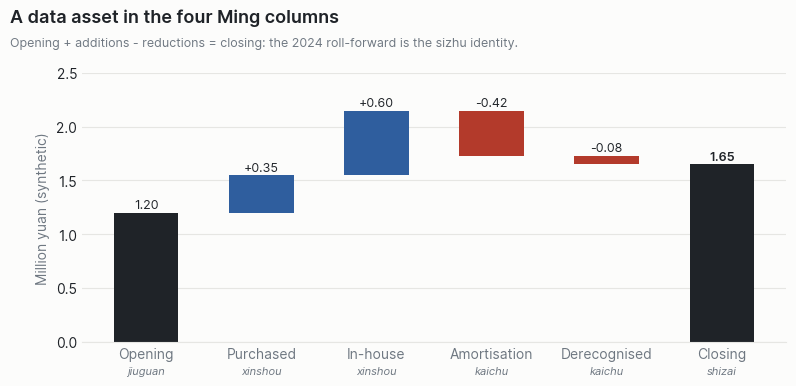

1.65

In [6]:
steps = [('Opening', 1.20), ('Purchased', 0.35), ('In-house', 0.60),
         ('Amortisation', -0.42), ('Derecognised', -0.08)]
closing = sum(v for _, v in steps)
fig, ax = plt.subplots(figsize=(8, 4.2))
level = 0
for i, (lab, v) in enumerate(steps):
    base = 0 if i == 0 else (level if v >= 0 else level + v)
    ax.bar(i, abs(v), bottom=base, width=0.56, color=INK if i == 0 else (WATER if v > 0 else LAND))
    ax.text(i, base + abs(v) + 0.04, f'{v:+.2f}' if i else f'{v:.2f}', ha='center', color=INK, fontsize=9)
    level = v if i == 0 else level + v
ax.bar(len(steps), closing, width=0.56, color=INK)
ax.text(len(steps), closing + 0.04, f'{closing:.2f}', ha='center', color=INK, fontsize=9, weight='semibold')
cols = ['jiuguan', 'xinshou', 'xinshou', 'kaichu', 'kaichu', 'shizai']
ax.set_xticks(range(len(steps) + 1), [s for s, _ in steps] + ['Closing'])
for i, c in enumerate(cols):
    ax.text(i, -0.30, c, ha='center', color=MUTED, fontsize=8, style='italic')
ax.set_ylim(0, 2.5); ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.tick_params(length=0); ax.spines['left'].set_visible(False); ax.set_ylabel('Million yuan (synthetic)')
fig.text(0.01, 0.96, 'A data asset in the four Ming columns', fontsize=13, weight='semibold', color=INK)
fig.text(0.01, 0.905, 'Opening + additions - reductions = closing: the 2024 roll-forward is the sizhu identity.', fontsize=9, color=MUTED)
fig.subplots_adjust(top=0.84, bottom=0.2, left=0.1, right=0.98)
fig.savefig(FIG / 'four_columns.png', dpi=150); plt.show()
round(closing, 2)

## 5. Six centuries on one line

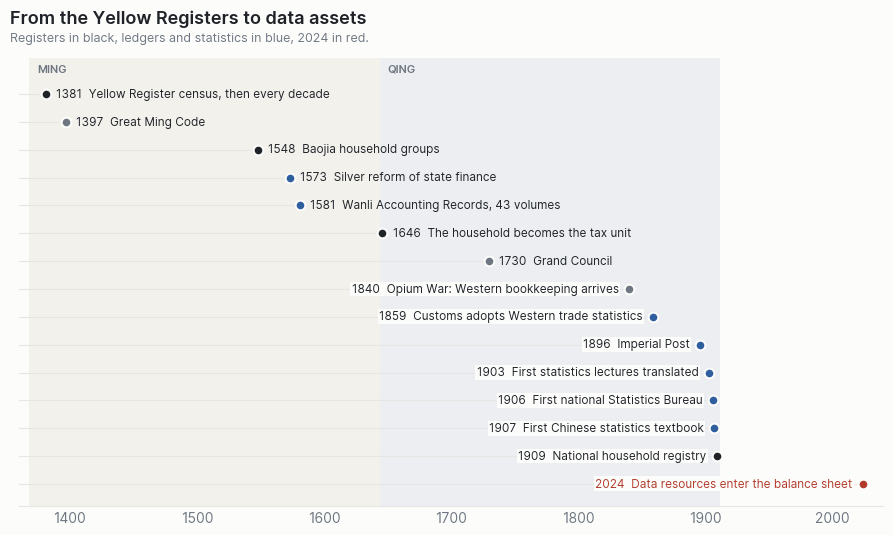

In [7]:
tl = tables['timeline'].sort_values('year').reset_index(drop=True)
short = {1381: 'Yellow Register census, then every decade', 1397: 'Great Ming Code', 1548: 'Baojia household groups',
         1573: 'Silver reform of state finance', 1581: 'Wanli Accounting Records, 43 volumes', 1646: 'The household becomes the tax unit',
         1730: 'Grand Council', 1840: 'Opium War: Western bookkeeping arrives', 1859: 'Customs adopts Western trade statistics',
         1896: 'Imperial Post', 1903: 'First statistics lectures translated', 1906: 'First national Statistics Bureau',
         1907: 'First Chinese statistics textbook', 1909: 'National household registry', 2024: 'Data resources enter the balance sheet'}
colour = {'register': INK, 'institution': MUTED, 'ledger': WATER, 'statistics': WATER, 'bridge': LAND}
fig, ax = plt.subplots(figsize=(9, 5.4))
ax.axvspan(1368, 1644, color='#F3F1EC', lw=0); ax.axvspan(1644, 1912, color='#ECEEF1', lw=0)
n = len(tl)
for i, r in tl.iterrows():
    y = n - 1 - i
    ax.plot([1360, r.year], [y, y], color=GRID, lw=0.8, zorder=1)
    ax.plot(r.year, y, 'o', ms=7, color=colour[r.category], mec=BG, mew=1.5, zorder=3)
    right = r.year < 1800
    ax.text(r.year + (8 if right else -8), y, f"{r.year}  {short[r.year]}", va='center',
            ha='left' if right else 'right', fontsize=8.5, color=LAND if r.category == 'bridge' else INK,
            bbox=dict(fc=BG, ec='none', pad=1) if not right else None)
ax.text(1374, n - 0.2, 'MING', color=MUTED, fontsize=8, weight='semibold')
ax.text(1650, n - 0.2, 'QING', color=MUTED, fontsize=8, weight='semibold')
ax.set_xlim(1360, 2040); ax.set_ylim(-0.8, n + 0.3); ax.set_yticks([])
ax.set_xticks([1400, 1500, 1600, 1700, 1800, 1900, 2000]); ax.tick_params(length=0)
ax.spines['left'].set_visible(False)
fig.text(0.01, 0.965, 'From the Yellow Registers to data assets', fontsize=13, weight='semibold', color=INK)
fig.text(0.01, 0.93, 'Registers in black, ledgers and statistics in blue, 2024 in red.', fontsize=9, color=MUTED)
fig.subplots_adjust(top=0.9, bottom=0.07, left=0.02, right=0.98)
fig.savefig(FIG / 'ledger_lineage.png', dpi=150); plt.show()

## 6. Reporting cadence and the people who measured

In [8]:
tables['reporting_calendar'][['dynasty', 'report', 'frequency_per_year', 'content']]

,dynasty,report,frequency_per_year,content
0,Ming,Triennial report,0.333,"four columns: opening, receipts, disbursements..."
1,Ming,Annual report,1.000,"four columns: annual levy, annual receipts, an..."
2,Ming,Semi-annual and quarterly report,4.000,"four columns: opening, receipts, disbursements..."
3,Ming,Monthly report,12.000,receipts and expenditure
4,Qing customs,Daily return,365.000,"ships, tonnage, goods, duties"
5,Qing customs,Monthly return,12.000,"ships, tonnage, goods, duties"
6,Qing customs,Quarterly return,4.000,"ships, tonnage, goods, duties"
7,Qing customs,Annual trade report,1.000,"trade by port, gold and silver, import and exp..."
8,Qing customs,Decennial report,0.100,"social, economic and administrative change aro..."


In [9]:
tables['thinkers'][['name', 'born', 'died', 'contribution']]

,name,born,died,contribution
0,Qiu Jun,1420,1495,compared grain transport series across years; ...
1,Zhang Juzheng,1525,1582,judged budgets on at least two years of data; ...
2,Xu Guangqi,1562,1633,built time series of locust outbreaks over thr...
3,Lu Xiangsheng,1600,1639,combined group means and overall means to esti...
4,Gu Yanwu,1613,1682,local surveys; argued that quantity standards ...
5,Hong Liangji,1746,1809,"population against food supply before Malthus,..."
6,Wei Yuan,1794,1857,statistics of foreign states; read the silver ...
7,Wang Shiduo,1802,1889,overpopulation as the cause of late Qing unrest
8,Peng Zuzhi,<NA>,<NA>,"first Chinese textbook of statistics, on Weste..."


## Findings

1. **The state ran on a closing identity.** The four-column report (opening + receipts − disbursements = closing) was the standard form from county to Ministry, monthly to triennially, for three centuries.
2. **Double entry grew locally.** Dragon Gate and four-legged books, merchant inventions, computed profit twice and checked that both halves met, before Western bookkeeping arrived through the customs service.
3. **Statistics came with the household.** Registers counted households, not heads; the 1909 registry even imputed population at a fixed 5.5 persons per household in the 18 provinces and 8.38 outside.
4. **The identity outlived the empire.** Chinese companies now report data resources with the same roll-forward. Old records explain the method; recent records carry the value for decisions.

## Known limits

- **One secondary source**, a synthesis of Chinese scholarship, read in translation. Names are romanised from Russian and checked against standard pinyin; some dates differ from other literature (Grand Council usually 1729 to 1733; Ming baojia often linked to earlier local practice).
- **Yingtianfu** is listed apart from South Zhili in the source table; kept as published.
- **Sections 3 and 4 are synthetic**: they illustrate the arithmetic, they are not historical or company accounts.

In [10]:
out = DATA / 'parquet'; out.mkdir(exist_ok=True)
for name, df in tables.items():
    df.to_parquet(out / f'{name}.parquet', index=False)
sorted(p.name for p in out.iterdir())

['ledger_methods.parquet', 'registers.parquet', 'relay_stations.parquet', 'reporting_calendar.parquet', 'thinkers.parquet', 'timeline.parquet']